# Chapter 4. Implementation
## 4.4 Bilateral Filtering Mapping

The pilot search selects the fixed spatial parameter $\sigma_s$. This setting is then used to calibrate $\sigma_r$ and validate the candidate mappings.


## 1. Fixed Spatial Parameter Selection

Five calibration images are used for the pilot search. The best overall spatial setting is kept for calibration.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed

# Find the project directory
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_dir) not in sys.path:
    sys.path.append(str(project_dir))

from src.denoisers import bilateral_denoise
from src.metrics import calculate_psnr
from src.noise import add_gaussian_noise
from src.utils import load_grayscale_image


In [2]:
# Experiment settings
noise_levels = [2, 4, 6, 8, 10, 12, 15]
seed = 42
num_calibration = 50
num_validation = 30
num_pilot = 5

spatial_values = [1, 2, 3, 4, 5]
coarse_range_values = [0.01, 0.02, 0.04, 0.06, 0.08, 0.12, 0.18, 0.26, 0.38, 0.50]

calibration_dir = project_dir / "data" / "calibration"
result_dir = project_dir / "results" / "Chapter4_BF_Calibration"
result_dir.mkdir(parents=True, exist_ok=True)

print("Calibration directory:", calibration_dir)
print("Noise levels (%):", noise_levels)
print("Spatial candidates:", spatial_values)
print("Seed:", seed)


Calibration directory: D:\MScProject\data\calibration
Noise levels (%): [2, 4, 6, 8, 10, 12, 15]
Spatial candidates: [1, 2, 3, 4, 5]
Seed: 42


In [3]:
# Find all image files
image_files = []
for pattern in ["*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif", "*.tiff"]:
    image_files.extend(calibration_dir.glob(pattern))

image_files = sorted(image_files)
required_images = num_calibration + num_validation

if len(image_files) < required_images:
    raise FileNotFoundError(
        f"At least {required_images} images are required, but only {len(image_files)} were found in {calibration_dir}"
    )

# Create reproducible calibration and validation sets
split_rng = np.random.default_rng(seed)
shuffled_indices = split_rng.permutation(len(image_files))
calibration_indices = shuffled_indices[:num_calibration]
validation_indices = shuffled_indices[num_calibration:required_images]

calibration_files = sorted([image_files[index] for index in calibration_indices])
validation_files = sorted([image_files[index] for index in validation_indices])

# Select five pilot images
pilot_rng = np.random.default_rng(seed)
pilot_indices = pilot_rng.choice(len(calibration_files), size=num_pilot, replace=False)
pilot_files = [calibration_files[index] for index in pilot_indices]
pilot_names = [image_file.stem for image_file in pilot_files]

# Load clean images
calibration_images = {
    image_file.stem: load_grayscale_image(image_file)
    for image_file in calibration_files
}
validation_images = {
    image_file.stem: load_grayscale_image(image_file)
    for image_file in validation_files
}

print("Number of calibration images:", len(calibration_images))
print("Calibration image IDs:")
print(", ".join(image_file.stem for image_file in calibration_files))

print("\nNumber of validation images:", len(validation_images))
print("Validation image IDs:")
print(", ".join(image_file.stem for image_file in validation_files))

print("\nNumber of pilot images:", len(pilot_files))
print("Pilot image IDs:")
print(", ".join(sorted(pilot_names)))


Number of calibration images: 50
Calibration image IDs:
004, 008, 009, 010, 021, 025, 026, 027, 030, 034, 038, 039, 047, 051, 052, 055, 057, 068, 071, 076, 080, 085, 093, 097, 102, 105, 107, 116, 122, 131, 134, 139, 145, 148, 149, 151, 153, 154, 158, 165, 172, 174, 177, 179, 188, 189, 190, 191, 197, 198

Number of validation images: 30
Validation image IDs:
001, 003, 005, 013, 028, 029, 033, 053, 056, 063, 067, 069, 081, 082, 083, 087, 089, 090, 095, 099, 104, 109, 113, 115, 119, 135, 144, 156, 181, 200

Number of pilot images: 5
Pilot image IDs:
021, 085, 139, 153, 198


In [4]:
# Search the spatial and range parameters on the five pilot images
def evaluate_pilot_candidates(image_name, noise_percent):
    clean_image = calibration_images[image_name]
    noisy_image = add_gaussian_noise(clean_image, sigma=noise_percent / 100, seed=seed).astype(np.float32)
    image_results = []

    for sigma_spatial_value in spatial_values:
        for sigma_range in coarse_range_values:
            denoised_image = bilateral_denoise(
                noisy_image, sigma_color=sigma_range, sigma_spatial=sigma_spatial_value
            )
            psnr = calculate_psnr(clean_image, denoised_image)

            image_results.append({
                "image": image_name,
                "noise_sigma": noise_percent,
                "sigma_spatial": sigma_spatial_value,
                "sigma_range": sigma_range,
                "psnr": psnr
            })

    return image_results


pilot_outputs = Parallel(n_jobs=16, prefer="threads", verbose=5)(
    delayed(evaluate_pilot_candidates)(image_name, noise_percent)
    for noise_percent in noise_levels
    for image_name in pilot_names
)

pilot_results = pd.DataFrame([row for output in pilot_outputs for row in output])
print("Pilot results:", len(pilot_results))


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  12 out of  35 | elapsed:  3.8min remaining:  7.4min
[Parallel(n_jobs=16)]: Done  20 out of  35 | elapsed:  4.8min remaining:  3.6min
[Parallel(n_jobs=16)]: Done  28 out of  35 | elapsed:  7.0min remaining:  1.7min


Pilot results: 1750


[Parallel(n_jobs=16)]: Done  35 out of  35 | elapsed:  7.5min finished


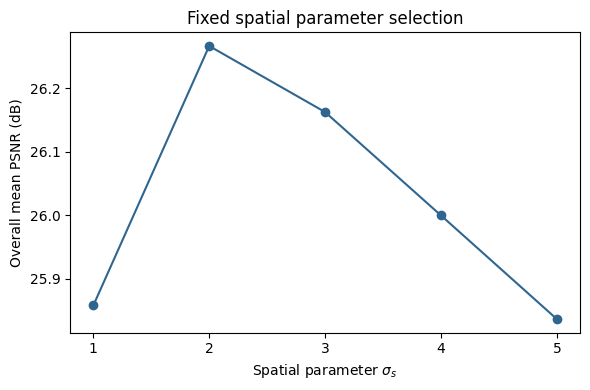

Selected fixed spatial parameter: σs = 2


,sigma_spatial,overall_mean_psnr
0,1,25.857696
1,2,26.266358
2,3,26.162302
3,4,25.999548
4,5,25.836264


,noise_sigma,sigma_spatial,sigma_range,psnr
0,2,2,0.02,34.519578
1,4,2,0.04,29.466276
2,6,2,0.08,26.834595
3,8,2,0.12,24.945007
4,10,2,0.12,23.793278
5,12,2,0.18,22.682241
6,15,2,0.18,21.623528


,noise_sigma,fine_range
0,2,"0.01, 0.02, 0.03, 0.04, 0.05, 0.06"
1,4,"0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08"
2,6,"0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.11,..."
3,8,"0.08, 0.09, 0.1, 0.11, 0.12, 0.13, 0.14, 0.15,..."
4,10,"0.08, 0.09, 0.1, 0.11, 0.12, 0.13, 0.14, 0.15,..."
5,12,"0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2, 0.21,..."
6,15,"0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2, 0.21,..."


In [5]:
# Average the pilot results across images
pilot_mean = pilot_results.groupby(
    ["noise_sigma", "sigma_spatial", "sigma_range"], as_index=False
)["psnr"].mean()

# Find the best range value for each spatial value and noise level
pilot_best_indices = pilot_mean.groupby(["noise_sigma", "sigma_spatial"])["psnr"].idxmax()
pilot_best_by_noise = (
    pilot_mean.loc[pilot_best_indices]
    .sort_values(["sigma_spatial", "noise_sigma"])
    .reset_index(drop=True)
)

# Select one spatial value using its mean of the noise-level optima
spatial_summary = (
    pilot_best_by_noise.groupby("sigma_spatial", as_index=False)["psnr"]
    .mean()
    .rename(columns={"psnr": "overall_mean_psnr"})
)

best_spatial_index = spatial_summary["overall_mean_psnr"].idxmax()
sigma_spatial = float(spatial_summary.loc[best_spatial_index, "sigma_spatial"])
if sigma_spatial.is_integer():
    sigma_spatial = int(sigma_spatial)

selected_pilot_best = (
    pilot_best_by_noise[pilot_best_by_noise["sigma_spatial"] == sigma_spatial]
    .sort_values("noise_sigma")
    .reset_index(drop=True)
)

# Build a fine range around each selected coarse optimum
fine_ranges = {}

for _, row in selected_pilot_best.iterrows():
    noise_percent = int(row["noise_sigma"])
    centre = float(row["sigma_range"])
    candidates = np.arange(centre - 0.04, centre + 0.041, 0.01)
    fine_ranges[noise_percent] = np.round(
        [value for value in candidates if 0.005 <= value <= 0.60], 3
    ).tolist()

    if centre == min(coarse_range_values) or centre == max(coarse_range_values):
        print(f"Warning: {noise_percent}% reached a coarse range-search boundary.")

if sigma_spatial in {min(spatial_values), max(spatial_values)}:
    print("Warning: the selected spatial value is at the search boundary.")

fine_range_table = pd.DataFrame({
    "noise_sigma": list(fine_ranges),
    "fine_range": [", ".join(map(str, values)) for values in fine_ranges.values()]
})

# Plot the fixed spatial parameter search
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(
    spatial_summary["sigma_spatial"], spatial_summary["overall_mean_psnr"],
    marker="o", color="#2F6690"
)
ax.set_xlabel(r"Spatial parameter $\sigma_s$")
ax.set_ylabel("Overall mean PSNR (dB)")
ax.set_title("Fixed spatial parameter selection")
ax.set_xticks(spatial_values)

fig.tight_layout()
fig.savefig(result_dir / "bf_fixed_spatial_search.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Selected fixed spatial parameter: σs = {sigma_spatial}")
display(spatial_summary)
display(selected_pilot_best)
display(fine_range_table)


## 2. Calibration

Using the selected $\sigma_s$, $\sigma_r$ is fine-tuned at each noise level on all fifty calibration images. The selected values are used to build three mappings.


In [6]:
# Run the fine range-parameter search on all calibration images
def evaluate_calibration_image(image_name, clean_image, noise_percent):
    noisy_image = add_gaussian_noise(clean_image, sigma=noise_percent / 100, seed=seed).astype(np.float32)
    image_results = []

    for sigma_range in fine_ranges[noise_percent]:
        denoised_image = bilateral_denoise(
            noisy_image, sigma_color=sigma_range, sigma_spatial=sigma_spatial
        )
        psnr = calculate_psnr(clean_image, denoised_image)

        image_results.append({
            "image": image_name,
            "noise_sigma": noise_percent,
            "seed": seed,
            "sigma_spatial": sigma_spatial,
            "sigma_range": sigma_range,
            "psnr": psnr
        })

    return image_results


fine_outputs = Parallel(n_jobs=16, prefer="threads", verbose=5)(
    delayed(evaluate_calibration_image)(image_name, clean_image, noise_percent)
    for noise_percent in noise_levels
    for image_name, clean_image in calibration_images.items()
)

grid_results = pd.DataFrame([row for output in fine_outputs for row in output])
print("Fine-search results:", len(grid_results))


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  40 tasks      | elapsed:   41.0s
[Parallel(n_jobs=16)]: Done 130 tasks      | elapsed:  2.0min
[Parallel(n_jobs=16)]: Done 256 tasks      | elapsed:  3.9min


Fine-search results: 2950


[Parallel(n_jobs=16)]: Done 350 out of 350 | elapsed:  5.1min finished


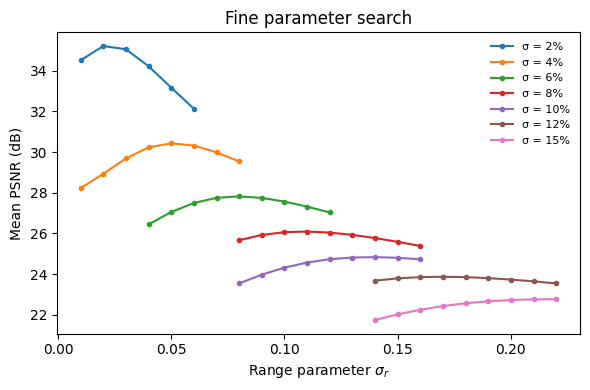

,noise_sigma,sigma_range,psnr
0,2,0.02,35.211123
1,4,0.05,30.431090
2,6,0.08,27.823817
3,8,0.11,26.095822
4,10,0.14,24.839805
5,12,0.17,23.874257
6,15,0.22,22.771178


In [7]:
# Average PSNR across the fifty calibration images
mean_results = grid_results.groupby(["noise_sigma", "sigma_range"], as_index=False)["psnr"].mean()

# Select the range parameter with the highest mean PSNR
best_indices = mean_results.groupby("noise_sigma")["psnr"].idxmax()
best_parameters = mean_results.loc[best_indices].sort_values("noise_sigma").reset_index(drop=True)

# Plot the fine-search curves
fig, ax = plt.subplots(figsize=(6, 4))

for noise_percent in noise_levels:
    current = mean_results[mean_results["noise_sigma"] == noise_percent]
    ax.plot(
        current["sigma_range"], current["psnr"],
        marker="o", markersize=3, label=f"σ = {noise_percent}%"
    )

ax.set_xlabel(r"Range parameter $\sigma_r$")
ax.set_ylabel("Mean PSNR (dB)")
ax.set_title("Fine parameter search")
ax.legend(frameon=False, fontsize=8)

fig.tight_layout()
fig.savefig(result_dir / "bf_fine_search.png", dpi=300, bbox_inches="tight")
plt.show()

best_parameters


Fixed spatial parameter: σs = 2
Mapping: σr = 0.0153σ + -0.0115
R² = 0.9996


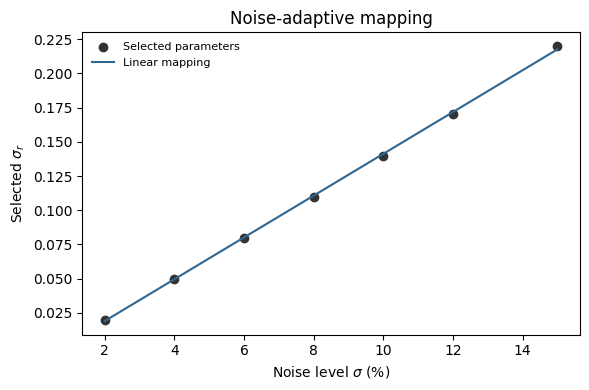

In [8]:
# Fit a linear noise-to-parameter mapping
noise_values = best_parameters["noise_sigma"].to_numpy(dtype=float)
range_values = best_parameters["sigma_range"].to_numpy(dtype=float)

slope, intercept = np.polyfit(noise_values, range_values, 1)
fitted_values = slope * noise_values + intercept

residual_sum = np.sum((range_values - fitted_values) ** 2)
total_sum = np.sum((range_values - np.mean(range_values)) ** 2)
r_squared = 1 - residual_sum / total_sum if total_sum > 0 else 0.0

minimum_range = float(range_values.min())
maximum_range = float(range_values.max())

mapping = pd.DataFrame({
    "sigma_spatial": [sigma_spatial],
    "slope": [slope],
    "intercept": [intercept],
    "r_squared": [r_squared],
    "minimum_range": [minimum_range],
    "maximum_range": [maximum_range]
})

print(f"Fixed spatial parameter: σs = {sigma_spatial}")
print(f"Mapping: σr = {slope:.4f}σ + {intercept:.4f}")
print(f"R² = {r_squared:.4f}")

# Plot the selected parameters and fitted mapping
fig, ax = plt.subplots(figsize=(6, 4))
plot_noise = np.linspace(min(noise_values), max(noise_values), 200)

ax.scatter(noise_values, range_values, color="#333333", label="Selected parameters")
ax.plot(plot_noise, slope * plot_noise + intercept, color="#2F6690", label="Linear mapping")
ax.set_xlabel(r"Noise level $\sigma$ (%)")
ax.set_ylabel(r"Selected $\sigma_r$")
ax.set_title("Noise-adaptive mapping")
ax.legend(frameon=False, fontsize=8)

fig.tight_layout()
fig.savefig(result_dir / "bf_parameter_mapping.png", dpi=300, bbox_inches="tight")
plt.show()


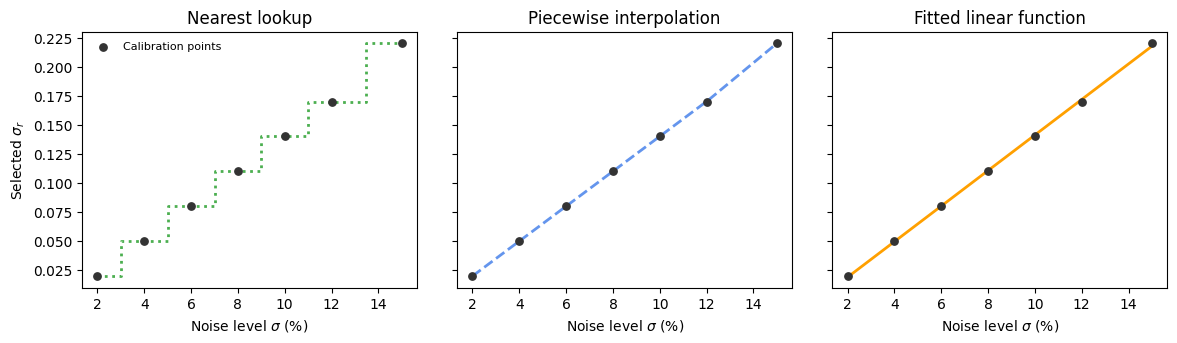

,noise_sigma,lookup_range,interpolated_range,fitted_range
0,2,0.02,0.020000,0.020000
1,3,0.02,0.035000,0.034302
2,4,0.05,0.050000,0.049577
3,5,0.05,0.065000,0.064851
4,6,0.08,0.080000,0.080126
5,7,0.08,0.095000,0.095400
6,8,0.11,0.110000,0.110675
7,9,0.11,0.125000,0.125950
8,10,0.14,0.140000,0.141224
9,11,0.14,0.155000,0.156499


In [9]:
# Define the three candidate mapping strategies
def select_bilateral_range_lookup(estimated_sigma_percent):
    distances = np.abs(noise_values - estimated_sigma_percent)
    nearest_index = int(np.argmin(distances))
    return float(range_values[nearest_index])


def select_bilateral_range_interpolated(estimated_sigma_percent):
    return float(np.interp(estimated_sigma_percent, noise_values, range_values))


def select_bilateral_range_fitted(estimated_sigma_percent):
    sigma_range = slope * estimated_sigma_percent + intercept
    return float(np.clip(sigma_range, minimum_range, maximum_range))


# Add noise levels between the calibration points
intermediate_noise_levels = [3, 5, 7, 9, 11, 13, 14]
validation_noise_levels = sorted(set(noise_levels + intermediate_noise_levels))

mapping_comparison = pd.DataFrame({
    "noise_sigma": validation_noise_levels,
    "lookup_range": [select_bilateral_range_lookup(value) for value in validation_noise_levels],
    "interpolated_range": [select_bilateral_range_interpolated(value) for value in validation_noise_levels],
    "fitted_range": [select_bilateral_range_fitted(value) for value in validation_noise_levels]
})

# Plot the three mapping strategies
plot_noise = np.linspace(min(noise_values), max(noise_values), 400)
lookup_plot = [select_bilateral_range_lookup(value) for value in plot_noise]
interpolated_plot = [select_bilateral_range_interpolated(value) for value in plot_noise]
fitted_plot = [select_bilateral_range_fitted(value) for value in plot_noise]

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)

axes[0].scatter(noise_values, range_values, color="#333333", s=28, label="Calibration points", zorder=4)
axes[0].step(plot_noise, lookup_plot, where="mid", color="#4CAF50", linewidth=2, linestyle=":")
axes[0].set_title("Nearest lookup")

axes[1].scatter(noise_values, range_values, color="#333333", s=28, zorder=4)
axes[1].plot(plot_noise, interpolated_plot, color="#6495ED", linewidth=2, linestyle="--")
axes[1].set_title("Piecewise interpolation")

axes[2].scatter(noise_values, range_values, color="#333333", s=28, zorder=4)
axes[2].plot(plot_noise, fitted_plot, color="#FFA000", linewidth=2)
axes[2].set_title("Fitted linear function")

for ax in axes:
    ax.set_xlabel(r"Noise level $\sigma$ (%)")

axes[0].set_ylabel(r"Selected $\sigma_r$")
axes[0].legend(frameon=False, fontsize=8)

fig.subplots_adjust(top=0.82, bottom=0.18, wspace=0.12)
fig.savefig(result_dir / "bf_mapping_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

mapping_comparison


## 3. Validation

The three mappings are evaluated on thirty validation images. Final selection uses the intermediate noise levels, which were not used in calibration.


In [10]:
# Evaluate the three mapping strategies on the validation images
def validate_image(image_name, clean_image, noise_percent):
    noisy_image = add_gaussian_noise(clean_image, sigma=noise_percent / 100, seed=seed).astype(np.float32)

    lookup_range = select_bilateral_range_lookup(noise_percent)
    interpolated_range = select_bilateral_range_interpolated(noise_percent)
    fitted_range = select_bilateral_range_fitted(noise_percent)

    lookup_image = bilateral_denoise(
        noisy_image, sigma_color=lookup_range, sigma_spatial=sigma_spatial
    )
    interpolated_image = bilateral_denoise(
        noisy_image, sigma_color=interpolated_range, sigma_spatial=sigma_spatial
    )
    fitted_image = bilateral_denoise(
        noisy_image, sigma_color=fitted_range, sigma_spatial=sigma_spatial
    )

    return {
        "image": image_name,
        "noise_sigma": noise_percent,
        "sigma_spatial": sigma_spatial,
        "lookup_range": lookup_range,
        "interpolated_range": interpolated_range,
        "fitted_range": fitted_range,
        "noisy_psnr": calculate_psnr(clean_image, noisy_image),
        "lookup_psnr": calculate_psnr(clean_image, lookup_image),
        "interpolated_psnr": calculate_psnr(clean_image, interpolated_image),
        "fitted_psnr": calculate_psnr(clean_image, fitted_image)
    }


validation_rows = Parallel(n_jobs=16, prefer="threads", verbose=5)(
    delayed(validate_image)(image_name, clean_image, noise_percent)
    for noise_percent in validation_noise_levels
    for image_name, clean_image in validation_images.items()
)

validation_results = pd.DataFrame(validation_rows)
validation_summary = validation_results.groupby("noise_sigma", as_index=False)[
    [
        "lookup_range", "interpolated_range", "fitted_range", "noisy_psnr",
        "lookup_psnr", "interpolated_psnr", "fitted_psnr"
    ]
].mean()

validation_summary["interpolation_minus_lookup"] = (
    validation_summary["interpolated_psnr"] - validation_summary["lookup_psnr"]
)
validation_summary["fitted_minus_lookup"] = (
    validation_summary["fitted_psnr"] - validation_summary["lookup_psnr"]
)

# Select the final strategy using only intermediate noise levels
intermediate_results = validation_results[
    validation_results["noise_sigma"].isin(intermediate_noise_levels)
]
mean_noisy_psnr = intermediate_results["noisy_psnr"].mean()

method_rows = []
for method_name, psnr_column in {
    "Nearest lookup": "lookup_psnr",
    "Piecewise interpolation": "interpolated_psnr",
    "Fitted linear function": "fitted_psnr"
}.items():
    mean_psnr = intermediate_results[psnr_column].mean()
    method_rows.append({
        "mapping_method": method_name,
        "mean_psnr": mean_psnr,
        "gain_over_noisy": mean_psnr - mean_noisy_psnr
    })

validation_method_summary = (
    pd.DataFrame(method_rows)
    .sort_values("mean_psnr", ascending=False)
    .reset_index(drop=True)
)

selected_mapping_method = validation_method_summary.loc[0, "mapping_method"]

print("Selected mapping method:", selected_mapping_method)
display(validation_summary)
display(validation_method_summary)


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  40 tasks      | elapsed:   15.1s
[Parallel(n_jobs=16)]: Done 130 tasks      | elapsed:   35.1s
[Parallel(n_jobs=16)]: Done 256 tasks      | elapsed:   59.1s


Selected mapping method: Piecewise interpolation


[Parallel(n_jobs=16)]: Done 420 out of 420 | elapsed:  1.6min finished


,noise_sigma,lookup_range,interpolated_range,fitted_range,noisy_psnr,lookup_psnr,interpolated_psnr,fitted_psnr,interpolation_minus_lookup,fitted_minus_lookup
0,2,0.02,0.020000,0.020000,33.945304,35.410723,35.410723,35.410723,0.000000,0.000000
1,3,0.02,0.035000,0.034302,30.423479,31.786691,32.598954,32.588670,0.812263,0.801979
2,4,0.05,0.050000,0.049577,27.924704,30.639637,30.639637,30.637556,0.000000,-0.002082
3,5,0.05,0.065000,0.064851,25.986504,28.883438,29.175555,29.175305,0.292117,0.291867
4,6,0.08,0.080000,0.080126,24.402879,28.022442,28.022442,28.022493,0.000000,0.000051
5,7,0.08,0.095000,0.095400,23.063943,26.941356,27.078047,27.077843,0.136690,0.136487
6,8,0.11,0.110000,0.110675,21.904104,26.277982,26.277982,26.277235,0.000000,-0.000747
7,9,0.11,0.125000,0.125950,20.881053,25.515515,25.585105,25.583740,0.069590,0.068226
8,10,0.14,0.140000,0.141224,19.965904,24.976889,24.976889,24.975004,0.000000,-0.001885
9,11,0.14,0.155000,0.156499,19.138050,24.398529,24.438358,24.436168,0.039829,0.037639


,mapping_method,mean_psnr,gain_over_noisy
0,Piecewise interpolation,26.506540,4.474625
1,Fitted linear function,26.504583,4.472668
2,Nearest lookup,26.302194,4.270278


In [11]:
# Show validation results at intermediate noise levels
validation_table = (
    validation_summary[validation_summary["noise_sigma"].isin(intermediate_noise_levels)][
        ["noise_sigma", "lookup_psnr", "interpolated_psnr", "fitted_psnr"]
    ]
    .rename(columns={
        "noise_sigma": "Noise level (%)",
        "lookup_psnr": "Nearest lookup",
        "interpolated_psnr": "Piecewise interpolation",
        "fitted_psnr": "Fitted linear function"
    })
    .round(3)
)

mean_row = pd.DataFrame({
    "Noise level (%)": ["Mean"],
    "Nearest lookup": [validation_table["Nearest lookup"].mean()],
    "Piecewise interpolation": [validation_table["Piecewise interpolation"].mean()],
    "Fitted linear function": [validation_table["Fitted linear function"].mean()]
}).round(3)

validation_table = pd.concat([validation_table, mean_row], ignore_index=True)
validation_table


,Noise level (%),Nearest lookup,Piecewise interpolation,Fitted linear function
0,3,31.787,32.599,32.589
1,5,28.883,29.176,29.175
2,7,26.941,27.078,27.078
3,9,25.516,25.585,25.584
4,11,24.399,24.438,24.436
5,13,23.499,23.528,23.528
6,14,23.091,23.142,23.143
7,Mean,26.302,26.507,26.505
